In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

print("GPU Devices:")
print(tf.config.list_physical_devices("GPU"))

print("\nCustom Model Environment Ready!")

TensorFlow Version: 2.21.0
GPU Devices:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Custom Model Environment Ready!


In [3]:
# Load IMDb dataset from Keras

from tensorflow.keras.datasets import imdb

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=10000
)

print("Dataset loaded successfully!")

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

print("First review (encoded):", x_train[0][:20])
print("First review label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Training samples: 25000
Testing samples: 25000
First review (encoded): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First review label: 1


In [4]:
# Analyze dataset

print("Training Dataset Analysis")
print("=========================")

print("Positive Reviews:", np.sum(y_train == 1))
print("Negative Reviews:", np.sum(y_train == 0))

review_lengths = [len(review) for review in x_train]

print("\nReview Length Analysis")
print("=========================")

print("Average Review Length:", np.mean(review_lengths))
print("Minimum Review Length:", np.min(review_lengths))
print("Maximum Review Length:", np.max(review_lengths))

Training Dataset Analysis
Positive Reviews: 12500
Negative Reviews: 12500

Review Length Analysis
Average Review Length: 238.71364
Minimum Review Length: 11
Maximum Review Length: 2494


In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LENGTH = 200

x_train_padded = pad_sequences(
    x_train,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

x_test_padded = pad_sequences(
    x_test,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Padding completed successfully!")

print("Training Data Shape:", x_train_padded.shape)
print("Testing Data Shape:", x_test_padded.shape)

print("First Padded Review:")
print(x_train_padded[0])

Padding completed successfully!
Training Data Shape: (25000, 200)
Testing Data Shape: (25000, 200)
First Padded Review:
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480  284    5  150    4  172  112  167    2  336  385   39    4
  172 4536 1111   17  546   38   13  447    4  192   50   16    6  147
 2025   19   14   22    4 1920 4613  469    4   22   71   87   12   16
   43  530   38   76   15   13 1247    4   22   17  515   17   12   16
  626   18    2    5   62  386   12    8  316    8  106    5    4 2223
 5244   16  480   66 3785   33    4  130   12   16   38  619    5   25
  124   51   36  135   48   25 1415   33    6   22   12  215   28   77
   52    5   14  407   16   82    2    8    4  107  117 5952   15  256
    4    2    7 3766    5  723   36   71   43  530  476   26  400  317
   46    7    4    2 1029   13  104   88    4  381   15  297   98   32
 2071   56   26  141    6  1

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

VOCAB_SIZE = 10000
EMBEDDING_DIM = 128

model = Sequential([

    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.5),

    Dense(1, activation="sigmoid")

])

print("Custom LSTM Model Created Successfully!")

Custom LSTM Model Created Successfully!


In [7]:
model.build(input_shape=(None, MAX_LENGTH))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Custom LSTM Model Compiled Successfully!")

print("Optimizer: Adam")
print("Loss Function: Binary Crossentropy")
print("Evaluation Metric: Accuracy")

Custom LSTM Model Compiled Successfully!
Optimizer: Adam
Loss Function: Binary Crossentropy
Evaluation Metric: Accuracy


In [9]:
EPOCHS = 5
BATCH_SIZE = 64
VALIDATION_SPLIT = 0.20

print("Training Configuration")
print("=======================")

print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Validation Split:", VALIDATION_SPLIT)

print("Training configuration ready!")

Training Configuration
Epochs: 5
Batch Size: 64
Validation Split: 0.2
Training configuration ready!


In [10]:
history = model.fit(
    x_train_padded,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    verbose=1
)

print("\nCustom LSTM Training Completed!")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.7190 - loss: 0.5532 - val_accuracy: 0.8312 - val_loss: 0.3980
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8655 - loss: 0.3381 - val_accuracy: 0.8550 - val_loss: 0.3558
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9103 - loss: 0.2420 - val_accuracy: 0.8530 - val_loss: 0.3510
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9265 - loss: 0.1970 - val_accuracy: 0.8284 - val_loss: 0.4394
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9509 - loss: 0.1386 - val_accuracy: 0.8528 - val_loss: 0.5590

Custom LSTM Training Completed!


In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Rebuild model from scratch

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

# Compile model

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early stopping callback

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=2,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

# Train model again

history = model.fit(
    x_train_padded,
    y_train,
    epochs=10,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[early_stopping],
    verbose=1
)

print("\nTraining with EarlyStopping Completed!")

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7188 - loss: 0.5424 - val_accuracy: 0.8316 - val_loss: 0.3997
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8541 - loss: 0.3496 - val_accuracy: 0.8562 - val_loss: 0.3430
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8972 - loss: 0.2659 - val_accuracy: 0.8568 - val_loss: 0.3590
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9379 - loss: 0.1783 - val_accuracy: 0.8582 - val_loss: 0.3821
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9531 - loss: 0.1358 - val_accuracy: 0.8534 - val_loss: 0.4526
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9644 - loss: 0.1043 - val_accuracy: 0.8330 - val_loss: 0.4986
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 4.

Training with EarlyStopping Completed!


In [12]:
test_loss, test_accuracy = model.evaluate(
    x_test_padded,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

print("\nFinal Custom LSTM Test Results")
print("================================")

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8474 - loss: 0.4048

Final Custom LSTM Test Results
Test Loss: 0.4048
Test Accuracy: 0.8474
Test Accuracy (%): 84.74%


In [13]:
from sklearn.metrics import classification_report, confusion_matrix

# Generate predictions

y_pred_prob = model.predict(
    x_test_padded,
    batch_size=BATCH_SIZE,
    verbose=1
)

y_pred = (y_pred_prob > 0.5).astype("int32").flatten()

# Classification report

class_names = ["Negative", "Positive"]

print("\nClassification Report")
print("==============================")

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix")
print("==============================")

print(cm)

391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step

Classification Report
              precision    recall  f1-score   support

    Negative       0.84      0.86      0.85     12500
    Positive       0.85      0.84      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000


Confusion Matrix
[[10726  1774]
 [ 2040 10460]]


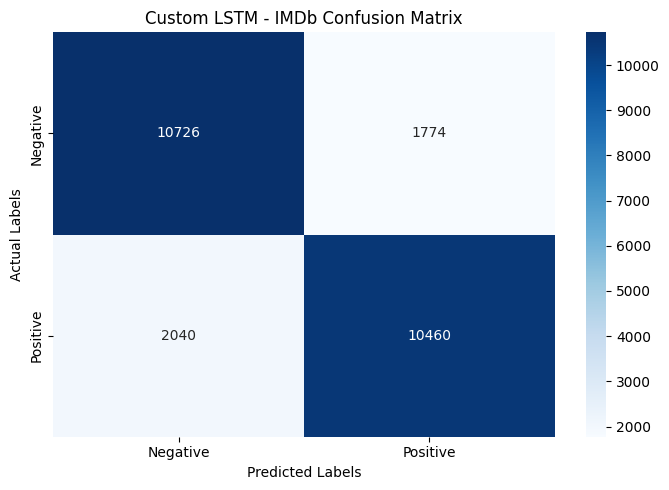

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom LSTM - IMDb Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.tight_layout()
plt.show()

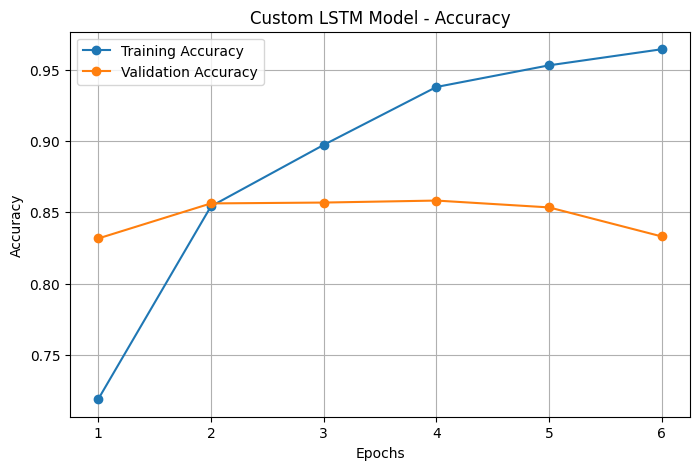

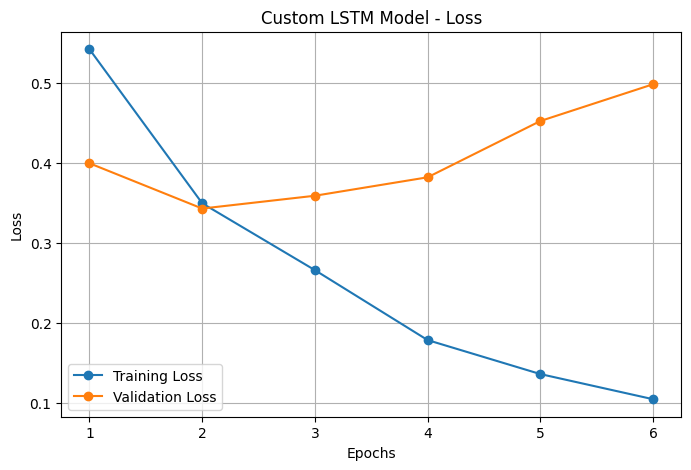

In [15]:
# Extract training history

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)


# Accuracy Graph

plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, marker="o", label="Validation Accuracy")

plt.title("Custom LSTM Model - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


# Loss Graph

plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_loss, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation Loss")

plt.title("Custom LSTM Model - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
# Save the trained custom LSTM model

model.save("IMDb_Custom_LSTM_Model.keras")

print("Custom LSTM Model saved successfully!")

Custom LSTM Model saved successfully!
